In [1]:
#base python
import glob
import os
import json
from dataclasses import dataclass, asdict
from collections import OrderedDict
import requests

#general types and utils
import PIL
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

#torch 
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import Compose, ColorJitter, ToTensor

#huggingface
from datasets import load_dataset, Image
from transformers import pipeline, AutoImageProcessor, AutoModel, Dinov2Model
from accelerate.test_utils.testing import get_backend

from diffusers import StableDiffusionXLPipeline
from diffusers.utils import is_xformers_available

I found this excellent repository! https://github.com/zacharyburkett/pca-object-recognition very useful for the hugging face api usage AND he just happens to be doing object recognition via PCA, so it's even aligned! I've been using it to explore how DINO features work.

Our goal is to process an image into a code that contains as much information about the content of the original image as possible.

Suppose such an encoding exists. How do we determine what components of a code correspond to which features of the original image?

Let's say we have an image of a woman in PPE during the pandemic.  How do we identify the surgical mask she might be wearing?

One way to do it is to encode the image, and then compare the resulting code to the codes of other images that contain the feature of interest. The information relating to the shared feature must be common between codes, and so are aligned along those dimensions related to that feature in the space of possible codes.

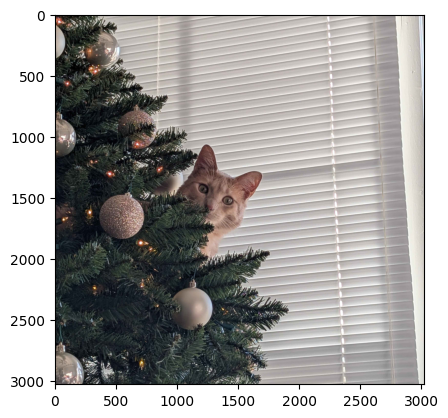

In [2]:
image = PIL.Image.open("Loki.jpg")
plt.imshow(np.array(image))

In [3]:
def plot_images(images, labels=None):
    figsize = 20 if len(images) > 1 else 10
    plt.figure(figsize=(figsize, figsize))
    for i, image in enumerate(images):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(image)
        plt.axis("off")
        if labels:
            plt.title(labels[i])
    plt.show()

In [4]:
img_size=1024
sdxl_model_id = "stabilityai/stable-diffusion-xl-base-1.0"

pipe = StableDiffusionXLPipeline.from_pretrained(sdxl_model_id, torch_dtype=torch.float16, variant="fp16").to("cuda")

pipe.enable_vae_slicing()
if is_xformers_available():
    pipe.enable_xformers_memory_efficient_attention()

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

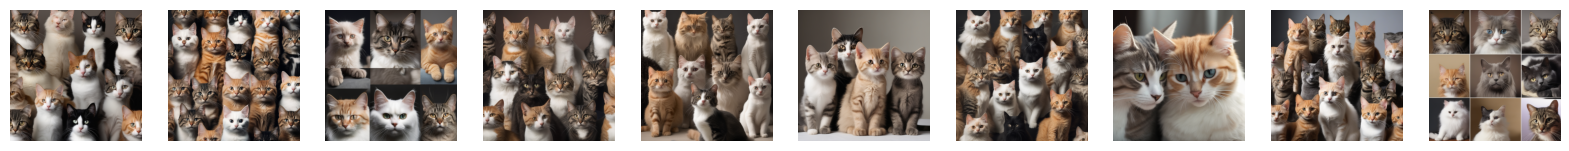

In [5]:
num_guides = 10

guide_images = pipe(
    prompt=["A high quality photo of cats."] * num_guides,
    guidance_scale=8.0,
    num_inference_steps=50,
).images

plot_images(guide_images)

In [6]:
dino_model_id = "facebook/dinov2-base"

image_processor = AutoImageProcessor.from_pretrained(dino_model_id, do_center_crop=False, do_resize=False)
model = Dinov2Model.from_pretrained(dino_model_id, device_map="cuda:0")

inputs = image_processor(images= guide_images, return_tensors="pt").to("cuda:0")

print(inputs['pixel_values'].shape)

with torch.inference_mode():
    outputs = model(**inputs)

print(outputs.last_hidden_state.shape)

patch_features = outputs.last_hidden_state[:, 1:, :] # remove the CLS token

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


torch.Size([10, 3, 1024, 1024])
torch.Size([10, 5330, 768])


In [7]:
def unflatten_features(features, batch_size=1, patch_size=14, img_size=1024):
    return features.reshape(batch_size, img_size // patch_size, img_size // patch_size, -1)

In [8]:
def thresholded_pca(x, n_components=3):
    # center the data
    x_mean = torch.mean(x, dim=0)
    x = x - x_mean

    # perform SVD and get principal components
    _, _, v = torch.svd(x)
    components = torch.mm(x, v[:, :n_components])

    # mask on positive primary component
    mask = components[:, 0] > 0

    # normalize
    min_val = torch.min(components)
    max_val = torch.max(components)
    components = (components - min_val) / (max_val - min_val)

    # apply threshold mask
    components = components * mask[:, None].float()

    return components


torch.Size([10, 5329, 768])
torch.Size([53290, 768])
torch.Size([53290, 3])
torch.Size([29465, 768])
torch.Size([10, 73, 73, 3])


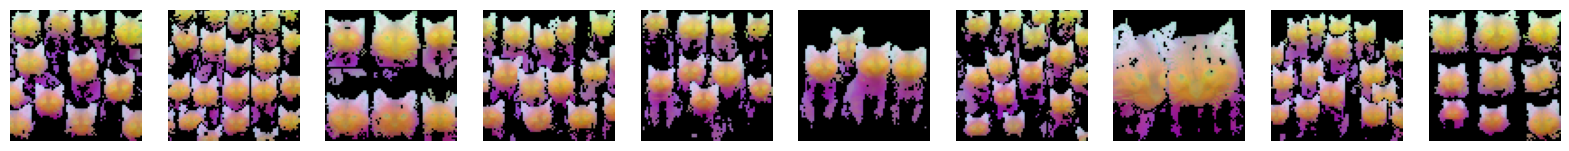

In [9]:
# extract guide patch features and flatten. These define the "feature of interest"
guide_patch_features = patch_features
print(guide_patch_features.shape)

#we don't care about batches in PCA, just gimme the vectors!
flat_guide_patch_features = guide_patch_features.reshape(-1, guide_patch_features.shape[-1]).cpu()
print(flat_guide_patch_features.shape)

# perform PCA and filter by thresholding on the primary component.  the feature of interest is most common, therefore those patches of the image with the feature will be defined by a large first principle conponent
pca_patch_features = thresholded_pca(flat_guide_patch_features)
print(pca_patch_features.shape)

#let's only keep those vectors corresponding to the feature
guide_patch_features_filtered = flat_guide_patch_features[pca_patch_features[:, 0] > 0]
print(guide_patch_features_filtered.shape)

# unflatten for display
pca_patch_features = unflatten_features(pca_patch_features, batch_size=num_guides)
print(pca_patch_features.shape)
plot_images(pca_patch_features)

<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=3028x3028 at 0x7F773C5ED270>


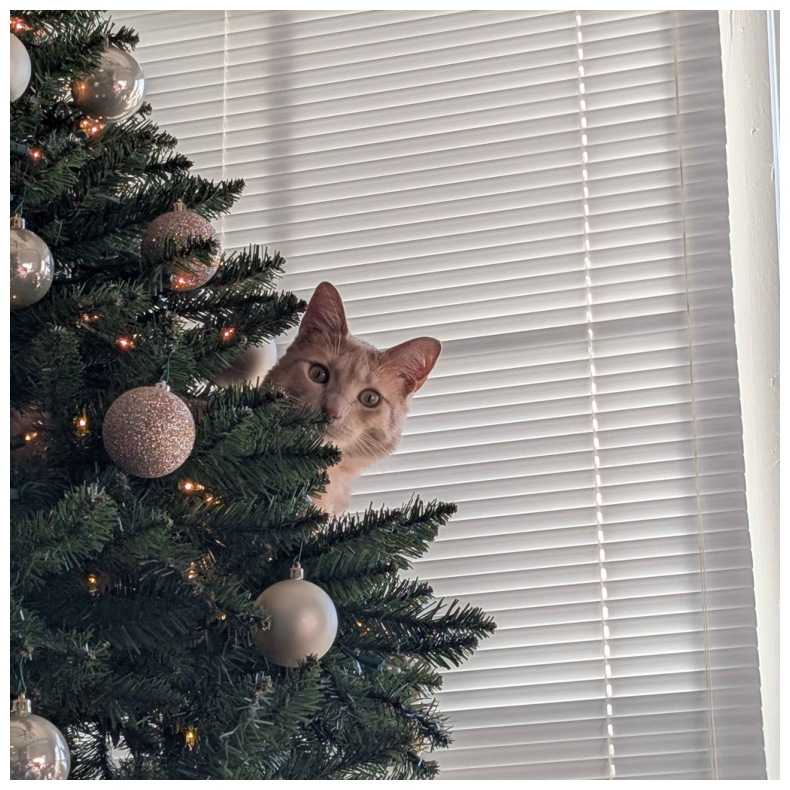

In [10]:
test_image = image
print(test_image)

target_size = 1024

test_image = test_image.resize((target_size, target_size))

plot_images([test_image])

In [11]:
test_inputs = image_processor(images=[test_image] + guide_images, return_tensors="pt").to("cuda:0")

with torch.inference_mode():
    outputs = model(**test_inputs)

test_patch_features = outputs.last_hidden_state[:, 1:, :]

<PIL.Image.Image image mode=RGB size=1024x1024 at 0x7F773C416E30>
torch.Size([73, 73, 3])


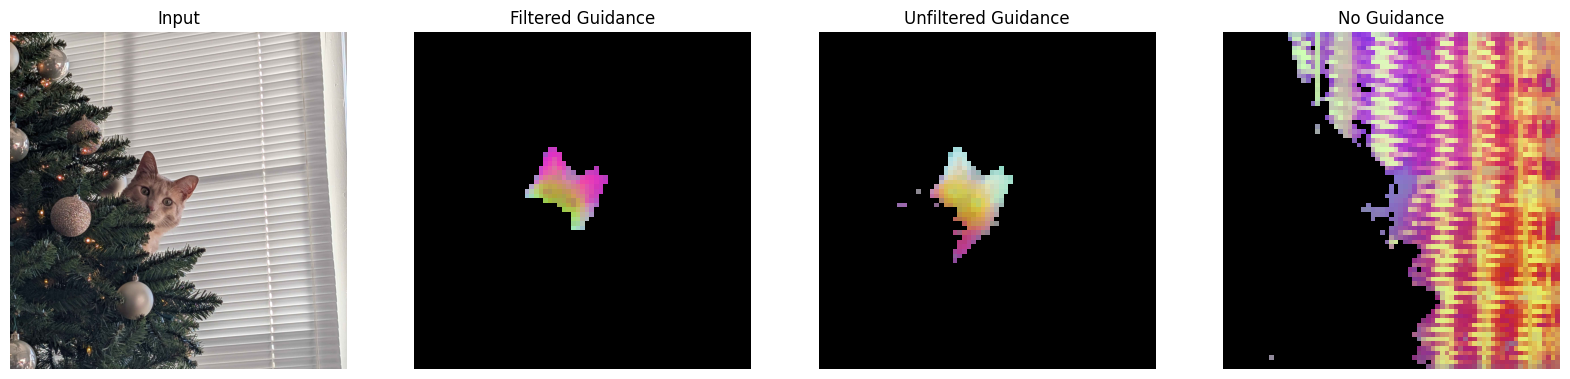

In [13]:
# perform combined PCA on input patches and filtered guide patches
input_patch_features = test_patch_features[0].cpu()

# get patches with filtered example data
pca_patch_features = thresholded_pca(
        torch.cat([input_patch_features, guide_patch_features_filtered], axis=0)
    )[:input_patch_features.shape[0]]

# get patches with unfiltered example data
pca_unfiltered_guidance = thresholded_pca(
        torch.cat([input_patch_features, flat_guide_patch_features], axis=0)
    )[:input_patch_features.shape[0]]

# get patches without example data
pca_no_guidance = thresholded_pca(input_patch_features)

feature_maps = [unflatten_features(f).squeeze(0) for f in [pca_patch_features, pca_unfiltered_guidance, pca_no_guidance]]

print(test_image)
print(feature_maps[0].shape)

plot_images([test_image] + feature_maps, labels=["Input", "Filtered Guidance", "Unfiltered Guidance", "No Guidance"])